# Medical imaging

## Practicum 1: Computed Tomography Image Visualisation & Reconstruction
Oct-Nov 2026
==============================================================================================

In this practicum, you will work with several topics covered in the theory sessions (Block 1). In particular you will (1) simulate a simple and more complex phantoms, (2) apply Radom forward transformation to simulate the computed tomography (CT) projections over a single slice (i.e., sinograms), and (3) reconstruct the original phantom intensity values using different image reconstruction algorithms. In addition, the Shepp–Logan (head) phantom will be used to analyse noise during reconstruction.

### Aims:
- Generate simple and complex phantoms.
- Understand the principles of CT image reconstruction using a fan beam geometry with the aid of ``skimage``.
- Be able to generate and understand image projections (i.e., sinograms).
- Reconstruct slices from simple and more complex objects (i.e., Shepp–Logan phantom) using back projection.
- Analyse and compare reconstructed data with ground truth data.
- Observe the difference between ideal (noise free) and noisy image reconstruction.

``Remember to comment your code and provide some discussion on the results obtained for each section.``



In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import radon

In [4]:
!pip install pydicom --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 23.9 MB/s eta 0:00:00


In [1]:
from google.colab import drive

try:
  drive.mount('/content/drive')
except Exception as e:
  print(e)

Mounted at /content/drive


### 1.1 Visualise a lung CT dicom image and create a phantom (2 points)

Open and visualise the Lung CT volume stored at the `LungCT-Diagnosis` accompanied folder. You can use mango viewer, ITK-Snap, etc. Then, using python commands, read each of the indivdual `dcm` images, and display some 2D slices. Some basic image processing might be needed to adjust the contrast/windows level for better visualisation of all tissues. Then, create a 3D phantom with the ribcages based on their HU (e.g., thresholding) and visualise the 3D rendering. Congratulations, you have created your first anthropomorphic phantom!

<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/LungPhantomImage.png?raw=1' width="400">


<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/LungPhantomRendering.png?raw=1' width="400">


Data was taken from https://www.cancerimagingarchive.net/collection/lungct-diagnosis/


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom as pdc
from pydicom.filereader import dcmread
from skimage.exposure import rescale_intensity
from skimage.morphology import ball, binary_opening, binary_closing, remove_small_objects
from skimage.measure import marching_cubes
from scipy.ndimage import gaussian_filter
import plotly.graph_objects as go

In [10]:
# ---------- 1) Read DICOM series ----------
DATA_DIR = Path("/content/drive/MyDrive/Medical Imaging/P1-student/P1-student/LungCT-Diagnosis")  # set to your dataset root

def read_series(dicom_dir: Path):
    files = sorted([p for p in dicom_dir.rglob("*.dcm")])
    assert files, f"No DICOMs under {dicom_dir}"
    # read all headers to sort by position or instance
    metas = []
    for f in files:
        ds = dcmread(str(f), stop_before_pixels=True, force=True)
        z = None
        if hasattr(ds, "ImagePositionPatient"):
            z = float(ds.ImagePositionPatient[2])
        inst = int(getattr(ds, "InstanceNumber", 0))
        metas.append((f, z, inst))
    # prefer ImagePositionPatient for sort, else InstanceNumber
    if all(m[1] is not None for m in metas):
        metas.sort(key=lambda x: x[1])
    else:
        metas.sort(key=lambda x: x[2])

# insert your code here
    slices = [dcmread(str(m[0]), stop_before_pixels=False) for m in metas]

    return {
        "pixels":            np.stack([s.pixel_array for s in slices]),                        # (n, rows, cols)
        "orientation":       np.array([s.ImageOrientationPatient for s in slices], dtype=float), # (n, 6)
        "position":          np.array([s.ImagePositionPatient for s in slices], dtype=float),    # (n, 3)
        "pixel_spacing":     np.array([s.PixelSpacing for s in slices], dtype=float),            # (n, 2)
        "slice_thickness":   np.array([s.get("SliceThickness", np.nan) for s in slices], dtype=float),
        "rescale_slope":     np.array([s.get("RescaleSlope", 1) for s in slices], dtype=float),
        "rescale_intercept": np.array([s.get("RescaleIntercept", 0) for s in slices], dtype=float),
        "instance_number":   np.array([s.get("InstanceNumber", 0) for s in slices], dtype=int),
        "files":             np.array([str(s.filename) for s in slices]),
    }


def slice_normals(d: dict) -> np.ndarray:
    """Unit vector perpendicular to each slice. Shape (n, 3)."""

    return np.cross(d["orientation"][:, :3], d["orientation"][:, 3:])


def slice_positions(d: dict) -> np.ndarray:
    """Distance of each slice along its normal, in mm. Shape (n,)."""

    return np.sum(d["position"] * slice_normals(d), axis=1)


def physical_order(d: dict) -> np.ndarray:
    """Index array that sorts slices by position along the stacking direction."""

    return np.argsort(slice_positions(d))


def rescale_pixels(pixels: np.ndarray, slope: np.ndarray, intercept: np.ndarray) -> np.ndarray:
    """Convert stored pixel values to real units (HU for CT), per slice."""

    return pixels.astype(np.float32) * slope[:, None, None] + intercept[:, None, None]


def compute_volume(d: dict, rescale: bool = True) -> np.ndarray:
    """Pixels in physical order. Shape (n, rows, cols). Real units if rescale=True."""

    order = physical_order(d)
    pixels = d["pixels"][order]
    if not rescale:
        return pixels
    return rescale_pixels(pixels, d["rescale_slope"][order], d["rescale_intercept"][order])


def compute_spacing(d: dict) -> np.ndarray:
    """Per-slice voxel size (dz, dy, dx) in mm. Shape (n, 3), physical order.

    dz for slice i is the gap to slice i-1; slice 0 reuses the first gap.
    """

    order = physical_order(d)
    gaps = np.diff(slice_positions(d)[order])
    dz = np.concatenate([gaps[:1], gaps])
    return np.column_stack([dz, d["pixel_spacing"][order]])


d = read_series(DATA_DIR)
vol = compute_volume(d)
spacing = compute_spacing(d)



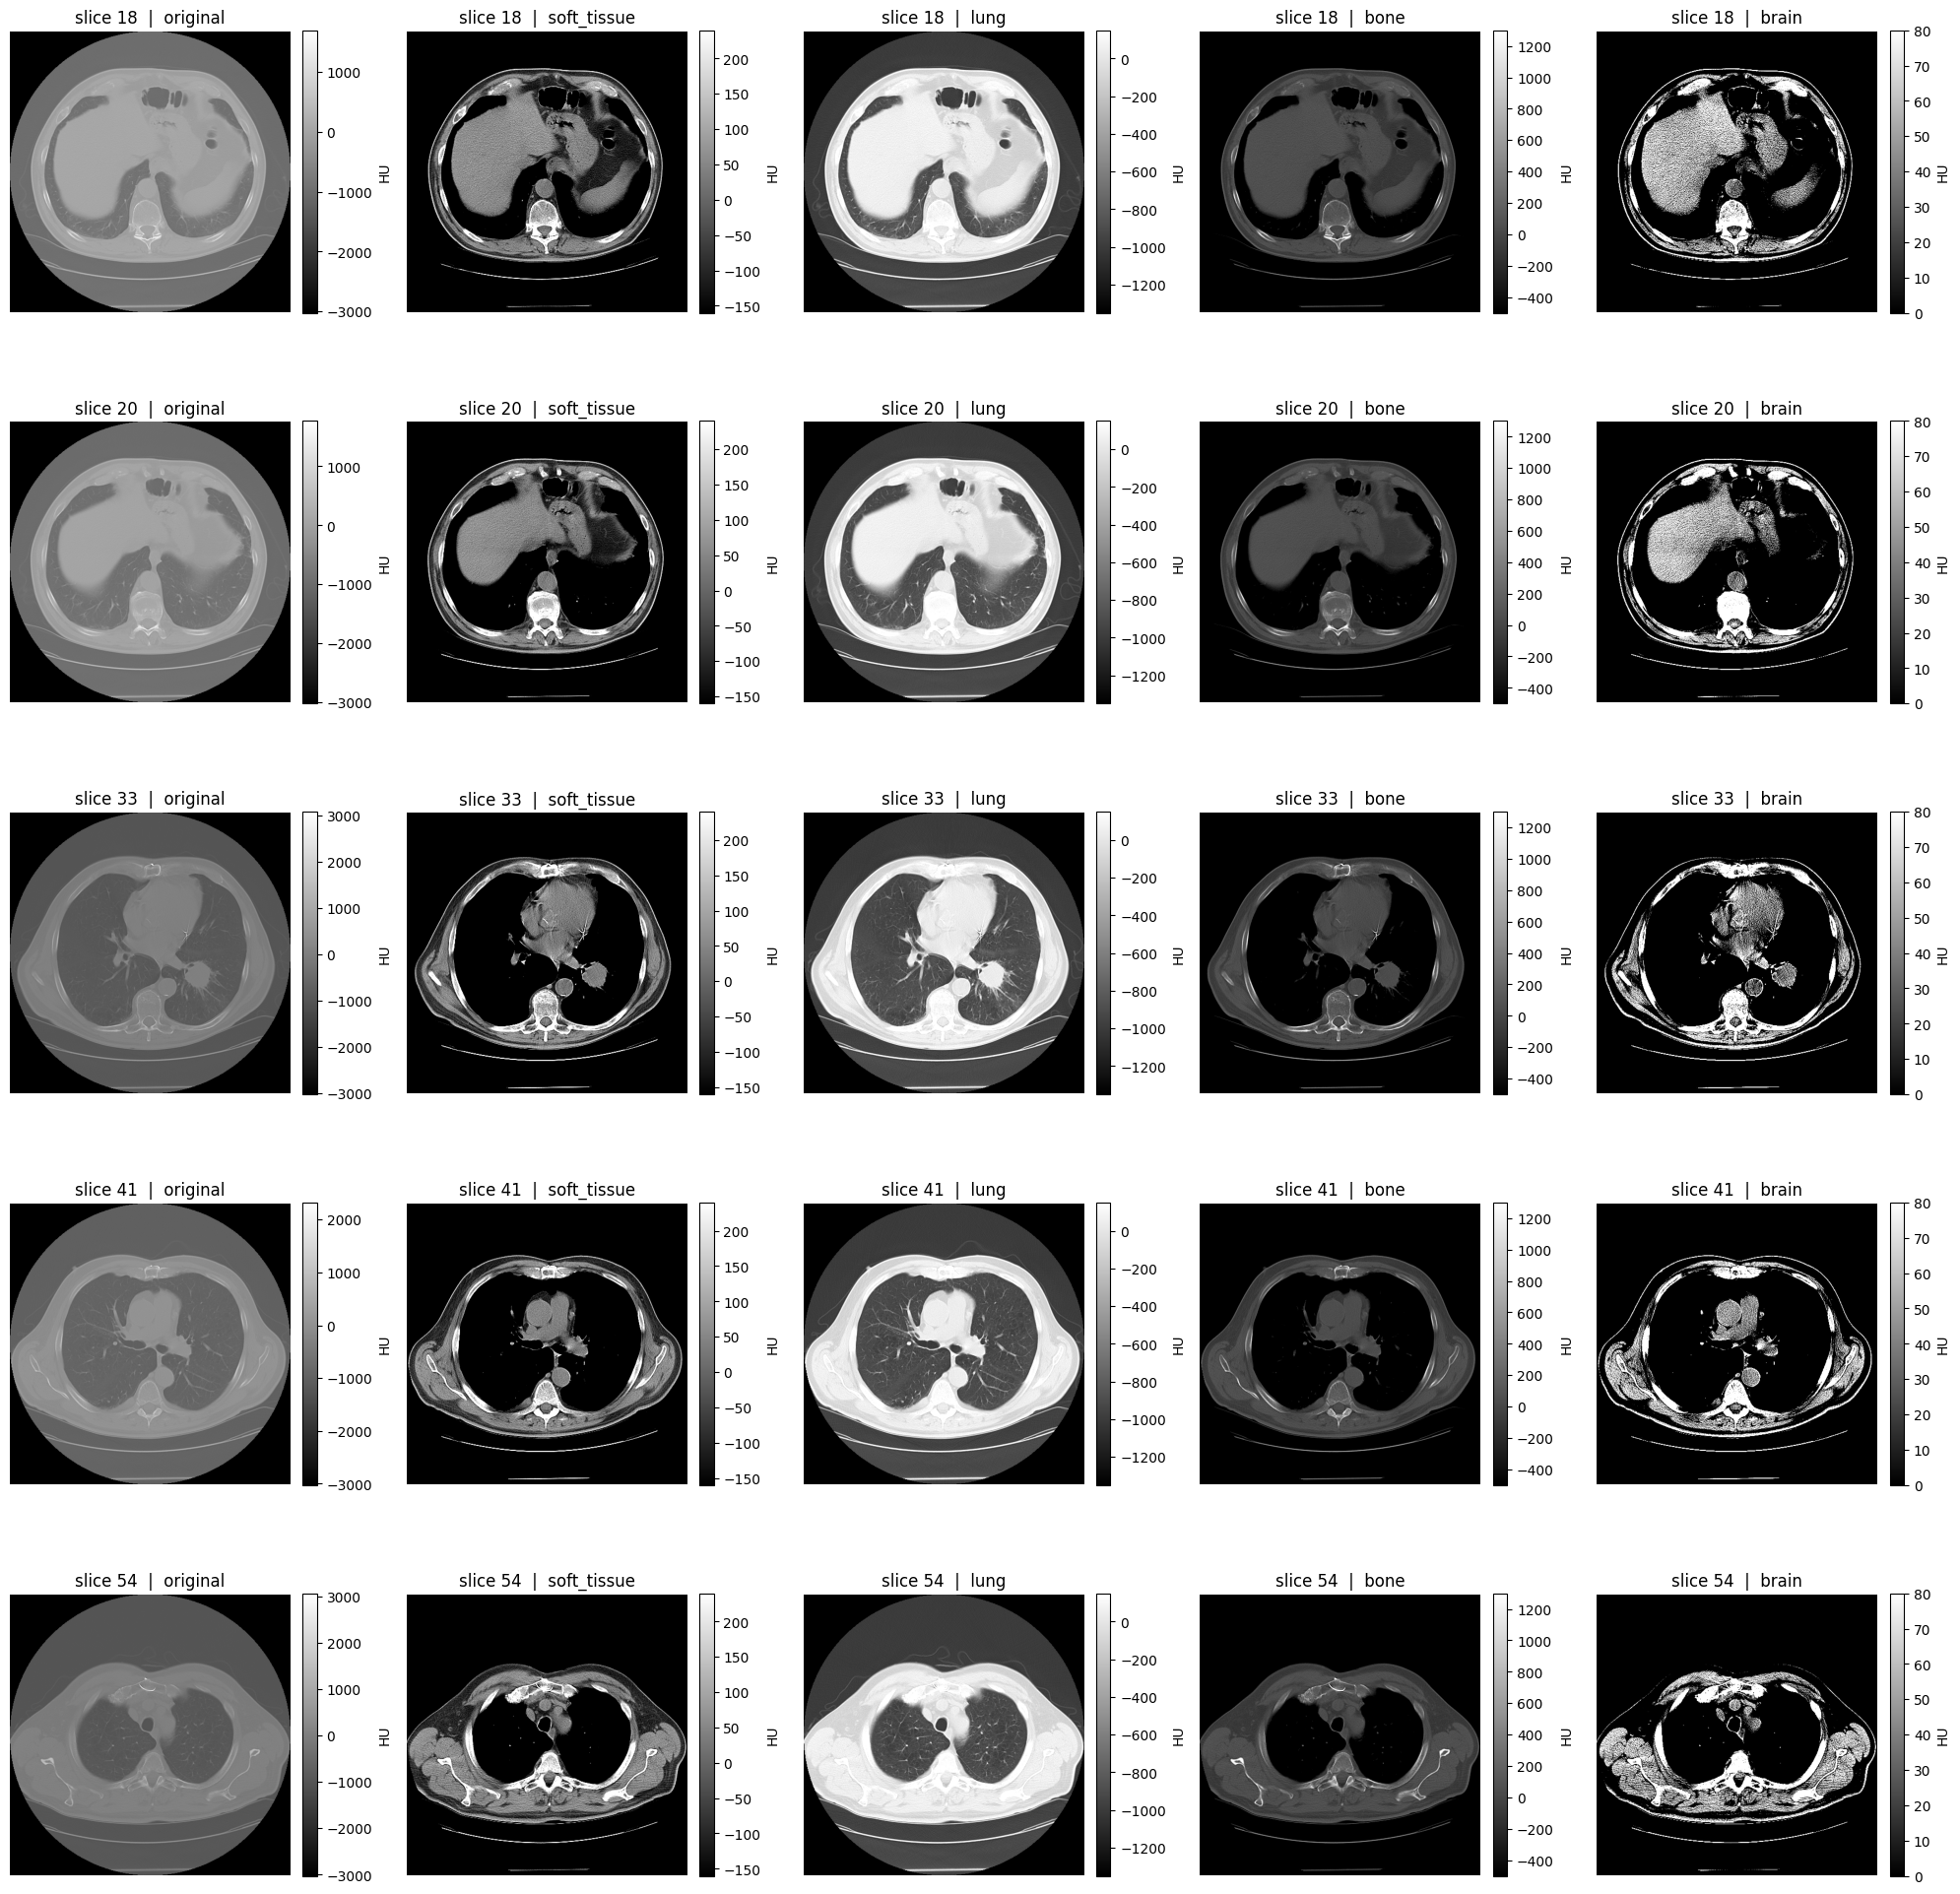

In [13]:
# ---------- 2) 2D visualisation with window/level ----------

# insert your code here

WINDOWS = {                      # (level, width) in HU
    "soft_tissue": (40, 400),
    "lung":        (-600, 1500),
    "bone":        (400, 1800),
    "brain":       (40, 80),
}


def window_range(level: float, width: float) -> tuple[float, float]:
    return level - width / 2, level + width / 2


def clip_to_window(img: np.ndarray, window: str) -> np.ndarray:
    """Clip HU values to the named window, keeping HU units."""
    rng = window_range(*WINDOWS[window])
    return rescale_intensity(img, in_range=rng, out_range=rng)


def random_indices(n_slices: int, n: int, seed: int | None = 0) -> np.ndarray:
    """n distinct slice indices, sorted."""
    return np.sort(np.random.default_rng(seed).choice(n_slices, size=n, replace=False))


def views_of(img: np.ndarray) -> dict[str, np.ndarray]:
    """Original plus every windowed version of one slice."""
    return {"original": img, **{w: clip_to_window(img, w) for w in WINDOWS}}


def draw(ax, img: np.ndarray, title: str) -> None:
    im = ax.imshow(img, cmap="gray")
    ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="HU")
    ax.set_title(title)
    ax.axis("off")


def show_random_slices(vol: np.ndarray, n: int = 5, seed: int | None = 0):
    """One row per random slice, one column per view, all in HU."""
    indices = random_indices(vol.shape[0], n, seed)
    n_cols = 1 + len(WINDOWS)
    fig, axes = plt.subplots(n, n_cols, figsize=(4 * n_cols, 4 * n))
    for row, idx in zip(axes, indices):
        for ax, (name, img) in zip(row, views_of(vol[idx]).items()):
            draw(ax, img, f"slice {idx}  |  {name}")
    fig.tight_layout()
    return fig


show_random_slices(vol, n=5)
plt.show()


In [14]:
# ---------- 3) Ribcage phantom via HU threshold ----------
# Simple bone mask. Typical cortical bone > 300 HU.
vol_hu = vol.astype(np.float32)
BONE_TH = 300.0
bone_mask = vol_hu >= BONE_TH

# insert your code here

import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.morphology import ball, binary_opening, binary_closing, remove_small_objects
from skimage.measure import label


def threshold_bone(vol: np.ndarray, th: float = BONE_TH, sigma: float = 0.5) -> np.ndarray:
    """Smooth lightly, then keep voxels above the HU threshold."""
    return gaussian_filter(vol, sigma) >= th


def clean_mask(mask: np.ndarray, open_r: int = 1, close_r: int = 2, min_size: int = 500) -> np.ndarray:
    """Remove speckle, fill small holes, drop tiny components."""
    mask = binary_opening(mask, ball(open_r))     # kills isolated bright voxels (noise, contrast vessels)
    mask = binary_closing(mask, ball(close_r))    # bridges small gaps in cortical bone
    return remove_small_objects(mask, min_size=min_size)


def keep_largest(mask: np.ndarray, n: int = 1) -> np.ndarray:
    """Keep the n largest connected components (ribcage + spine form one)."""
    labels = label(mask, connectivity=1)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0                                   # ignore background
    keep = np.argsort(sizes)[::-1][:n]
    return np.isin(labels, keep)


def ribcage_mask(vol: np.ndarray, th: float = BONE_TH) -> np.ndarray:
    return keep_largest(clean_mask(threshold_bone(vol, th)))


bone_mask = ribcage_mask(vol_hu)
print("bone voxels:", bone_mask.sum(), f"({100 * bone_mask.mean():.2f} % of volume)")


bone voxels: 525872 (2.95 % of volume)


In [15]:
# ---------- 4) 3D rendering with marching cubes ----------
# Marching cubes expects z-y-x ordering and voxel spacing.


# insert your code here
import numpy as np
import plotly.graph_objects as go
from skimage.measure import marching_cubes


def mask_to_mesh(mask: np.ndarray, spacing: np.ndarray, step: int = 1):
    """Surface of a binary mask in mm. Returns (verts (V,3) as z,y,x; faces (F,3))."""
    verts, faces, _, _ = marching_cubes(
        mask.astype(np.uint8), level=0.5,
        spacing=tuple(spacing[0]),          # (dz, dy, dx); validated equal for all slices
        step_size=step,
    )
    return verts, faces


def mesh_figure(verts: np.ndarray, faces: np.ndarray, color: str = "lightgray") -> go.Figure:
    """Interactive plotly figure of one mesh. Axes relabelled to patient x, y, z."""
    z, y, x = verts.T
    mesh = go.Mesh3d(x=x, y=y, z=z,
                     i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                     color=color, opacity=1.0, flatshading=True,
                     lighting=dict(ambient=0.4, diffuse=0.8, specular=0.2))
    fig = go.Figure(mesh)
    fig.update_layout(
        scene=dict(xaxis_title="x (mm)", yaxis_title="y (mm)", zaxis_title="z (mm)",
                   aspectmode="data"),             # keep true proportions
        width=800, height=800, margin=dict(l=0, r=0, t=0, b=0),
    )
    return fig


verts, faces = mask_to_mesh(bone_mask, spacing, step=2)
print(f"{len(verts):,} vertices, {len(faces):,} faces")
mesh_figure(verts, faces).show()


84,146 vertices, 169,254 faces


### 1.2 Create a simple and homogeneous phantom (1.5 points)

Now create from scratch a more simple 2D phantom which contains a fake (bright) lesion as shown below:

<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/PhantomImage.png?raw=1' width="400">

- Phantom size: 256 x 256 pixels.
- Phantom must contain 3 tissues:
    - Background = 0 pixel intensity value
    - Tissue 1 = 1 (radius = 100 pixels)
    - Tissue 2 (lesion) = 2 (radius = 5 pixels)
    
Help: To create the circunferences, you can use the function ``create_circular_mask``, or define your own function. The lesion can be placed anywhere within the phantom, except at the exact center.

Once constructed, add a second lesion in the same row (same size and pixel intensity), plot the original phantom and a pixel intensity (horizontal) profile along the synthetic lesions, similarly as shown above (but with two lesions). Always remember to include the units of the axis when ploting a graph.

``Questions``: What challenges did you face? How did you deal with them?

In [ ]:
def create_circular_mask(h, w, center=None, radius=None):

    if center is None: # use the middle of the image
        center = (int(w/2), int(h/2))
    if radius is None: # use the smallest distance between the center and image walls
        radius = min(center[0], center[1], w-center[0], h-center[1])

    Y, X = np.ogrid[:h, :w]
    dist_from_center = np.sqrt((X - center[0])**2 + (Y-center[1])**2)

    mask = dist_from_center <= radius
    return mask
# https://newbedev.com/how-can-i-create-a-circular-mask-for-a-numpy-array

In [ ]:
# insert your code here



### 1.3 Create the projections of the phantom (2 points)

Generate the projections of the previously generated 2D phantom using the ``radon`` transform from ``skimage.transform``. Play with the different parameters to optimise sinogram. Then, show the sinogram of the projections.

In this section, considered the following approch:

Use different number of projections (i.e. 4, 20, 50, 100, 200, 300, 360) considering that in all cases the simulated projections cover the 360º. For example, 100 projections are taken in the range from 0º to 360º.


``Questions``: How do the sinograms changes with number of projections? What is the effect of increasing/decrasing the number of projections?

In [ ]:
# insert your code here


### 1.4 Reconstruction with Filtered Back Projection (FBP) (2.5 points)

FBP is one of the most simple reconstruction methods to reconstruct images in CT. Explore the ``iradon`` from ``skimage.transform`` using the different filters available (Ramp filter (default), Shepp-logan, Cosine, Hamming, Hann).

Make use of the ``matplotlib`` to show the original and reconstructed images of the phantom and compare the pixel intensity signal across the lesion profile (similarly to section 2.1).In addition, provide evaluation metric you could consider useful for this purpose (image difference, mean square error (MSE), peak signal to noise ratio (PSNR), structural index similarity (SSIM), etc.). Then, discuss the results.

In [ ]:
# insert your code here


### 1.5 Sheep logan phantom (2 points)

So far we have used a quite simple phantom with only 2 tissues. Now, repeat the prior analysis for the **noisy sinogram** for one case (approach, filter,...) using a (slightly) more advanced head test object, the Sheep-logan phantom. Do you observe particular differences between the reconstrucction results from both phantoms?


<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/SheepLoganPhantom.png?raw=1' width="1000">



In order to create **noisy sinograms**, you can add Poison noise (``np.random.poisson``; perhaps with lam = 10) to your noise-free sinograms (not to the image!) and reconstruct the phantom images with the different filters. Plot the reconstruction image and the (horizontal) intensity profile along specific row. Then, comment on the effects of the filters on the reconstructed phatom images.


In [ ]:
from skimage.data import shepp_logan_phantom

logan_phantom = shepp_logan_phantom()


# insert your code here



###  Generative AI Declaration Policy
If generative AI tools were used in completing this practicum, you must explicitly declare their use. If you used AI, please include response the following three points:
1. ``Purpose``: A brief explanation of what you used generative AI for (e.g., brainstorming, proofreading, code debugging, or structuring ideas).
2. ``Sample Prompt``: At least one example of a prompt you submitted to the AI.
3. ``Refinement Process``: A short description of how you handled the prompt and evaluated the output (e.g., how you verified the facts, refined the wording, or altered the prompt to get better results).

In [ ]:
# answer here



### Group Organisation and Contribution

Since this assignment is a group project, your team must include a text addressing the following three points:
1. ``Task Organization``: Describe how your team organised the workflow to complete the entire notebook (e.g., who was responsible for which sections, how you collaborated, and how you merged your work).

2. ``Conflict Resolution``: Explain how you handled any discrepancies, disagreements, or differing opinions regarding the project's technical approach or final answers.

3. ``Percentage Contribution``: State the exact percentage of effort and contribution made by each member. The total sum across all three members must equal exactly 100% (e.g., Member A: 33.333%, Member B: 33.333%, Member C: 33.333%).


In [ ]:
# answer here

